#### 1. Inisialisasi library & Import dataset

In [ ]:
import pandas as pd
import numpy as np
import re

# Import dataset
df = pd.read_csv(Dataset - UAS.csv)

# Menampilkan 5 data pertama
df.head()

NameError: name 'Dataset' is not defined

#### 2. Periksa Struktur dataset

In [31]:
# Melihat jumlah baris dan kolom
print("Ukuran dataset:", df.shape)

# Melihat informasi setiap kolom
df.info()

# Melihat jumlah missing value
print("\nMissing Value:")
print(df.isnull().sum())

Ukuran dataset: (1176, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1176 entries, 0 to 1175
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Foto          1176 non-null   object
 1   Kelompok      1176 non-null   object
 2   No            1176 non-null   int64 
 3   Tanggal       1168 non-null   object
 4   Nama Produk   1175 non-null   object
 5   Jumlah Bibit  1172 non-null   object
 6   Harga         1172 non-null   object
 7   Ukuran Botol  1165 non-null   object
dtypes: int64(1), object(7)
memory usage: 73.6+ KB

Missing Value:
Foto             0
Kelompok         0
No               0
Tanggal          8
Nama Produk      1
Jumlah Bibit     4
Harga            4
Ukuran Botol    11
dtype: int64


#### 3. Data Cleaning

#### 3.1 Kolom Nama Produk

In [37]:
# Menghitung nama produk kosong dan unik
print("Missing value:", df['Nama Produk'].isnull().sum())
print("Jumlah nama produk unik:", df['Nama Produk'].nunique())

# Menampilkan beberapa nama produk
print("\nContoh nama produk:")
print(df['Nama Produk'].dropna().unique()[:30])

Missing value: 1
Jumlah nama produk unik: 452

Contoh nama produk:
['Scandalous' 'Zara Midnight' 'Dior Sauvage' 'Cleopatra' 'Black Opium'
 'Pick Up' 'X... Libra (nama kurang jelas)' 'Parfum Laundry J.Lo'
 'J.Lo Live Lux' 'Dunhill Blue' 'Romantic Wish'
 'Romantic W (nama kurang jelas)' 'Lovers x Baccarat Red'
 'Tonight Golden ... Fashion (nama kurang jelas)' 'Tonight' 'Baccarat Red'
 'Miss Dior' 'Golden Fashion' 'Scandal' 'Mancera Rose Vanilla'
 'Selena Gomez (nama perlu konfirmasi)' 'Vanilla' 'Laundry J.Lo'
 'Mancera Coco Vanilla' '212 VIP Black' 'Ashanti (++)' 'Scandal x Dunhill'
 'Malena Zain (nama perlu konfirmasi)' 'Hugo Boss'
 'Dunhill Blue x Scandalous']


##### 3.1.1 Normalisasi Nama Produk

In [38]:
# Membuat kolom nama produk normal
df['Nama Produk Normal'] = (
    df['Nama Produk']
    .str.strip()
    .str.title()
)

print("Jumlah nama produk unik sebelum:", df['Nama Produk'].nunique())
print("Jumlah nama produk unik sesudah:", df['Nama Produk Normal'].nunique())

Jumlah nama produk unik sebelum: 452
Jumlah nama produk unik sesudah: 369


##### 3.1.2 Pemeriksaan Variasi Nama

In [39]:
# Mengelompokkan nama berdasarkan hasil normalisasi
variasi_nama = df.groupby('Nama Produk Normal')['Nama Produk'].unique()

for nama, variasi in variasi_nama.items():
    if len(variasi) > 1:
        print(nama, ":", list(variasi))

212 Vip : ['212 Vip', '212 VIP']
212 Vip Black : ['212 VIP Black', '212 Vip Black', '212 VIP black']
Anna Sui Fancy : ['Anna Sui Fancy', 'Anna Sui Fancy ']
Ashanti : ['Ashanti', 'ashanti']
B. Aqua : ['B. Aqua', 'B. aqua']
Baccarat Dubai : ['Baccarat Dubai', 'Baccarat dubai']
Baccarat Red : ['Baccarat Red', 'Baccarat red', 'baccarat red']
Black Opium : ['Black Opium', 'black opium', 'Black opium']
Bulgari Aqua : ['Bulgari aqua', 'Bulgari Aqua']
Bulgari Rose : ['Bulgari Rose', 'bulgari rose', 'Bulgari rose']
Chanel Platinum : ['chanel platinum', 'Chanel platinum', 'Chanel Platinum']
Cleo Patra : ['Cleo Patra', 'cleo patra', 'cleo patra ', 'Cleo patra']
Cleopatra : ['Cleopatra', 'cleopatra']
Cristina Aquilera : ['cristina aquilera', 'Cristina Aquilera']
Dior Sauvage : ['Dior Sauvage', 'dior sauvage']
Dunhil Blue : ['Dunhil blue', 'Dunhil Blue']
Dunhill Blue : ['Dunhill Blue', 'Dunhill blue', 'Dunhill Blue ']
Elie Saab : ['Elie Saab', 'Elie Saab ']
Escada Cherry : ['Escada Cherry', 'Escada

##### 3.1.3 Koreksi Nama Produk

In [40]:
kamus_koreksi = {
    'achanti': 'Ashanti',
    'arhanti': 'Ashanti',
    'asanti': 'Ashanti',
    'christina aquilera': 'Christina Aguilera',
    'cristina aquilera': 'Christina Aguilera',
    'eli saab': 'Elie Saab',
    'escoda cherry': 'Escada Cherry',
    'jaquar vision': 'Jaguar Vision',
    'blurgari aqua': 'Bulgari Aqua',
    'romatic wish': 'Romantic Wish',
    'dunhil blue': 'Dunhill Blue',
    'taylor swif': 'Taylor Swift',
    'vanila': 'Vanilla',
    'ysi libre': 'YSL Libre'
}

df['Nama Produk Normal'] = (
    df['Nama Produk Normal']
    .str.lower()
    .map(lambda x: kamus_koreksi.get(x, x.title()) if pd.notna(x) else x)
)

print("Jumlah nama produk unik setelah koreksi:",
      df['Nama Produk Normal'].nunique())

Jumlah nama produk unik setelah koreksi: 357


##### 3.1.4 Hasil Cleaning Nama Produk

In [41]:
berubah = hasil_nama[
    hasil_nama['Nama Produk'].str.strip().str.lower() !=
    hasil_nama['Nama Produk Normal'].str.strip().str.lower()
]

display(berubah)

NameError: name 'hasil_nama' is not defined

#### 3.2 Cleaning Kolom Jumlah Bibit

In [42]:
print("Missing value:", df['Jumlah Bibit'].isnull().sum())
print("Jumlah nilai unik:", df['Jumlah Bibit'].nunique())

display(df['Jumlah Bibit'].value_counts().head(30))

Missing value: 4
Jumlah nilai unik: 85


Jumlah Bibit
20    248
10    143
12     78
14     64
1      59
30     59
15     56
8      53
5      37
6      34
50     29
9      27
25     25
28     24
17     21
4      20
24     16
13     16
26     13
11     12
40     11
2      11
16     10
18      9
7       8
23      6
19      4
-       4
27      3
70      3
Name: count, dtype: int64

##### 3.2.1 Periksa Format Khusus

In [43]:
# Menampilkan nilai yang mengandung simbol +, -, atau .
format_khusus = df[
    df['Jumlah Bibit'].astype(str).str.contains(r'[+\-.]', na=False)
]

display(format_khusus[['Nama Produk', 'Jumlah Bibit']])

,Nama Produk,Jumlah Bibit
15,Lovers x Baccarat Red,7+8
50,Dunhill Blue x Scandalous,5+8
54,Zara Gardenia,8 + 9 ml
95,Scandalous x Tonight,6+24
117,Black Opium x Escada C.,10+10
236,Dior Sauvage x Dunhil blue,20.10
249,Tonight x Paris Hilton Women,6 + 14
251,Lovely x scandalous,9 + 9
267,one million + Taylor Swift,7 + 5
271,Selena gomes x escada Cherry,10 + 10


##### 3.2.2 Transformasi Jumlah Bibit
Membuat kolom Komposisi Bibit untuk menyimpan rincian jumlah bibit dan Total Bibit untuk menyimpan hasil penjumlahannya.

In [44]:
def proses_bibit(nilai):
    if pd.isna(nilai) or str(nilai).strip() == '-':
        return np.nan

    teks = str(nilai).lower().replace('ml', '').replace(' ', '')

    if teks == '20.10':
        return [20, 10]

    if teks == '9.5':
        return [9.5]

    angka = re.split(r'[+-]', teks)

    try:
        return [float(x) for x in angka if x]
    except ValueError:
        return np.nan


df['Komposisi Bibit'] = df['Jumlah Bibit'].apply(proses_bibit)

df['Total Bibit'] = df['Komposisi Bibit'].apply(
    lambda x: sum(x) if isinstance(x, list) else np.nan
)

display(df[['Nama Produk', 'Jumlah Bibit', 'Komposisi Bibit', 'Total Bibit']].head(20))

,Nama Produk,Jumlah Bibit,Komposisi Bibit,Total Bibit
0,Scandalous,9,[9.0],9.0
1,Zara Midnight,24,[24.0],24.0
2,Zara Midnight,15,[15.0],15.0
3,Dior Sauvage,10,[10.0],10.0
4,Cleopatra,15,[15.0],15.0
5,Black Opium,19,[19.0],19.0
6,Dior Sauvage,10,[10.0],10.0
7,Pick Up,14,[14.0],14.0
8,X... Libra (nama kurang jelas),15,[15.0],15.0
9,Parfum Laundry J.Lo,1,[1.0],1.0


##### 3.2.3 Validasi Jumlah Bibit

In [45]:
print("Missing komposisi bibit:", df['Komposisi Bibit'].isnull().sum())
print("Missing total bibit:", df['Total Bibit'].isnull().sum())

# Melihat data dengan komposisi lebih dari satu angka
display(
    df[df['Komposisi Bibit'].apply(
        lambda x: isinstance(x, list) and len(x) > 1
    )][['Nama Produk', 'Jumlah Bibit', 'Komposisi Bibit', 'Total Bibit']]
)

Missing komposisi bibit: 8
Missing total bibit: 8


,Nama Produk,Jumlah Bibit,Komposisi Bibit,Total Bibit
15,Lovers x Baccarat Red,7+8,"[7.0, 8.0]",15.0
50,Dunhill Blue x Scandalous,5+8,"[5.0, 8.0]",13.0
54,Zara Gardenia,8 + 9 ml,"[8.0, 9.0]",17.0
95,Scandalous x Tonight,6+24,"[6.0, 24.0]",30.0
117,Black Opium x Escada C.,10+10,"[10.0, 10.0]",20.0
236,Dior Sauvage x Dunhil blue,20.10,"[20, 10]",30.0
249,Tonight x Paris Hilton Women,6 + 14,"[6.0, 14.0]",20.0
251,Lovely x scandalous,9 + 9,"[9.0, 9.0]",18.0
267,one million + Taylor Swift,7 + 5,"[7.0, 5.0]",12.0
271,Selena gomes x escada Cherry,10 + 10,"[10.0, 10.0]",20.0


#### 3.3 Cleaning Kolom Ukuran Botol

In [46]:
print("Missing value:", df['Ukuran Botol'].isnull().sum())
print("Jumlah nilai unik:", df['Ukuran Botol'].nunique())

display(df['Ukuran Botol'].value_counts().head(30))

Missing value: 11
Jumlah nilai unik: 60


Ukuran Botol
-             546
20 ml         161
15 ml          85
10 ml          51
30 ml          45
20ml           43
50 ml          34
15ml           31
28 ml          25
1              14
10ml           12
25 ml          11
30ml           10
20 Ml           8
28ml            8
50ml            8
15 Ml           5
8 ml            5
12 ml           5
30 Ml           5
Roll            4
14 ml           3
8ml             2
12 ml Roll      2
8 Ml            2
10 Ml           2
roll            2
2 ml            2
50 Ml           2
4 ml            2
Name: count, dtype: int64

##### 3.3.1 Transformasi Ukuran Botol ke Format Numerik

In [47]:
# Fungsi untuk membersihkan dan mengubah ukuran botol menjadi angka
def proses_ukuran(nilai):

    # Jika nilainya kosong atau berisi tanda '-', ubah menjadi NaN
    if pd.isna(nilai) or str(nilai).strip() == '-':
        return np.nan

    # Mengubah teks menjadi huruf kecil dan menghapus spasi di awal/akhir
    teks = str(nilai).strip().lower()

    # Mengambil angka di awal teks, baik yang diikuti 'ml' maupun tidak
    cocok = re.match(r'^(\d+(?:\.\d+)?)\s*(?:ml)?', teks)

    # Jika angka ditemukan, ubah menjadi tipe numerik
    if cocok:
        return float(cocok.group(1))

    # Jika tidak ditemukan angka, ubah menjadi NaN
    return np.nan


# Menerapkan fungsi pada kolom Ukuran Botol
df['Ukuran Botol (ml)'] = df['Ukuran Botol'].apply(proses_ukuran)


# Menampilkan jumlah missing value setelah konversi
print("Missing setelah konversi:", df['Ukuran Botol (ml)'].isnull().sum())

# Menampilkan daftar ukuran botol yang unik
print("Nilai ukuran unik:")
print(sorted(df['Ukuran Botol (ml)'].dropna().unique()))

Missing setelah konversi: 563
Nilai ukuran unik:
[np.float64(1.0), np.float64(2.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(8.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(20.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(30.0), np.float64(31.0), np.float64(35.0), np.float64(40.0), np.float64(48.0), np.float64(50.0), np.float64(65.0)]


##### 3.3.2 Mengatasi Missing Value Ukuran Botol

In [48]:
# Mengidentifikasi baris dengan ukuran botol bertanda '-'
mask_strip = df['Ukuran Botol'].astype(str).str.strip() == '-'

# Mengisi ukuran botol '-' menggunakan Total Bibit
df.loc[mask_strip, 'Ukuran Botol (ml)'] = df.loc[mask_strip, 'Total Bibit']

# Menampilkan jumlah missing value setelah pengisian
print("Missing setelah pengisian:", df['Ukuran Botol (ml)'].isnull().sum())

# Menampilkan beberapa data hasil pengisian
display(
    df.loc[mask_strip, [
        'Nama Produk', 'Jumlah Bibit',
        'Total Bibit', 'Ukuran Botol (ml)'
    ]].head(15)
)

Missing setelah pengisian: 21


,Nama Produk,Jumlah Bibit,Total Bibit,Ukuran Botol (ml)
3,Dior Sauvage,10,10.0,10.0
4,Cleopatra,15,15.0,15.0
8,X... Libra (nama kurang jelas),15,15.0,15.0
9,Parfum Laundry J.Lo,1,1.0,1.0
10,J.Lo Live Lux,10,10.0,10.0
14,Romantic W (nama kurang jelas),8,8.0,8.0
17,Tonight,14,14.0,14.0
20,Baccarat Red,4,4.0,4.0
21,Black Opium,12,12.0,12.0
23,Romantic Wish,12,12.0,12.0


##### 3.3.3 Identifikasi Ukuran Botol yang Tidak Wajar

In [49]:
# Menampilkan frekuensi setiap ukuran botol
print("Frekuensi ukuran botol:")
print(df['Ukuran Botol (ml)'].value_counts().sort_index())

# Menampilkan data dengan ukuran botol 1 ml
print("\nData dengan ukuran botol 1 ml:")
display(
    df[df['Ukuran Botol (ml)'] == 1][
        ['Nama Produk', 'Jumlah Bibit', 'Ukuran Botol', 'Ukuran Botol (ml)']
    ]
)

Frekuensi ukuran botol:
Ukuran Botol (ml)
0.0         1
1.0        58
2.0        10
4.0        18
5.0        26
6.0        21
7.0         7
8.0        41
9.0         9
10.0      146
11.0        8
12.0       60
13.0        5
14.0       38
15.0      153
16.0       10
17.0        8
18.0        9
19.0        2
20.0      299
23.0        4
24.0        7
25.0       16
26.0        6
27.0        1
28.0       42
29.0        2
30.0       81
31.0        1
33.0        1
35.0        4
40.0        5
45.0        1
48.0        3
50.0       50
65.0        1
1250.0      1
Name: count, dtype: int64

Data dengan ukuran botol 1 ml:


,Nama Produk,Jumlah Bibit,Ukuran Botol,Ukuran Botol (ml)
9,Parfum Laundry J.Lo,1,-,1.0
36,Laundry J.Lo,1,1 (kemungkinan ukuran/isi; perlu konfirmasi),1.0
59,Parfum Laundry,1,-,1.0
72,Parfum Laundry,1,-,1.0
74,Parfum Laundry,1,-,1.0
80,Laundry,1,-,1.0
82,Laundry,1,-,1.0
93,Parfum Laundry,1,-,1.0
105,Laundry Day,1,-,1.0
144,Lindung Sakura,1,-,1.0


##### Koreksi data ukuran botol yang anomali

In [50]:
# Ubah anomali 1250 menjadi NaN
df.loc[df['Ukuran Botol'] == 1250, 'Ukuran Botol'] = np.nan
df.loc[df['Ukuran Botol'] == '1250', 'Ukuran Botol'] = np.nan

print("Berhasil! Nilai anomali 1250 pada Jumlah Bibit dan Ukuran Botol sudah diubah menjadi NaN.")

# Menampilkan bukti perubahan khusus untuk produk Jio Summer
print("\n=== BUKTI PERUBAHAN JIO SUMMER ===")
display(
    df[df['Nama Produk Normal'].str.contains(
        'Jio Summer', case=False, na=False
    )][['Nama Produk Normal', 'Jumlah Bibit', 'Ukuran Botol', 'Harga']]
)

Berhasil! Nilai anomali 1250 pada Jumlah Bibit dan Ukuran Botol sudah diubah menjadi NaN.

=== BUKTI PERUBAHAN JIO SUMMER ===


,Nama Produk Normal,Jumlah Bibit,Ukuran Botol,Harga
367,Jio Summer,28,30ml,70.000
739,Jio Summer,28,-,70.000
990,Jio Summer,24,-,60.000
1009,Jio Summer,20,20 ml,50.000
1010,Jio Summer,20,20 ml,50.000
1011,Jio Summer,20,20 ml,50.000
1021,Jio Summer + Salena A.,1250,-,50.000
1040,Jio Summer,20,20ml,50.000
1078,Salena G & Jio Summer,8+12,-,50.000
1110,Jio Summer,70,20ml,50.000


##### 3.3.4 Mengatasi Ukuran Botol Tidak Valid
Mengubah seluruh ukuran 1 ml menjadi missing value (NaN) karena ukuran botolnya belum dapat dipastikan

In [51]:
# Mengubah ukuran botol 1 ml menjadi missing value
df.loc[df['Ukuran Botol (ml)'] == 1, 'Ukuran Botol (ml)'] = np.nan

# Menampilkan jumlah missing value setelah koreksi
print("Missing setelah koreksi:", df['Ukuran Botol (ml)'].isnull().sum())

# Menampilkan frekuensi ukuran botol setelah koreksi
print("\nFrekuensi ukuran botol:")
print(df['Ukuran Botol (ml)'].value_counts().sort_index())

Missing setelah koreksi: 79

Frekuensi ukuran botol:
Ukuran Botol (ml)
0.0         1
2.0        10
4.0        18
5.0        26
6.0        21
7.0         7
8.0        41
9.0         9
10.0      146
11.0        8
12.0       60
13.0        5
14.0       38
15.0      153
16.0       10
17.0        8
18.0        9
19.0        2
20.0      299
23.0        4
24.0        7
25.0       16
26.0        6
27.0        1
28.0       42
29.0        2
30.0       81
31.0        1
33.0        1
35.0        4
40.0        5
45.0        1
48.0        3
50.0       50
65.0        1
1250.0      1
Name: count, dtype: int64


##### 3.3.5 Identifikasi Ukuran Botol Tidak Wajar

In [52]:
# Menampilkan data dengan ukuran botol 0 ml atau 1250 ml
display(
    df[df['Ukuran Botol (ml)'].isin([0, 1250])][
        ['Nama Produk', 'Jumlah Bibit', 'Total Bibit',
         'Ukuran Botol', 'Ukuran Botol (ml)']
    ]
)

,Nama Produk,Jumlah Bibit,Total Bibit,Ukuran Botol,Ukuran Botol (ml)
935,Cleo Patra,0,0.0,-,0.0
1021,Jio summer + salena a.,1250,1250.0,-,1250.0


##### 3.3.6 Koreksi Ukuran Botol Tidak Valid
Ubah 2 ukuran botol tidak valid menjadi missing value

In [53]:
# Mengubah ukuran 0 ml dan 1250 ml menjadi missing value
df.loc[
    df['Ukuran Botol (ml)'].isin([0, 1250]),
    'Ukuran Botol (ml)'
] = np.nan

# Memeriksa jumlah missing value setelah koreksi
print("Missing setelah koreksi:", df['Ukuran Botol (ml)'].isnull().sum())

# Memeriksa ukuran terkecil dan terbesar
print("Ukuran terkecil:", df['Ukuran Botol (ml)'].min())
print("Ukuran terbesar:", df['Ukuran Botol (ml)'].max())

Missing setelah koreksi: 81
Ukuran terkecil: 2.0
Ukuran terbesar: 65.0


##### 3.3.7 Pemeriksaan Format Ukuran Botol Tidak Jelas

In [54]:
# Menampilkan data yang ukuran aslinya tidak diawali angka
mask_tidak_jelas = pd.to_numeric(
    df['Ukuran Botol'].astype(str).str.extract(r'^(\d+)')[0],
    errors='coerce'
).isna()

# Mengecualikan data kosong dan tanda '-'
mask_tidak_jelas &= df['Ukuran Botol'].notna()
mask_tidak_jelas &= df['Ukuran Botol'].astype(str).str.strip() != '-'

# Menampilkan data yang perlu diperiksa
display(
    df.loc[mask_tidak_jelas, [
        'Nama Produk', 'Ukuran Botol', 'Ukuran Botol (ml)'
    ]]
)

,Nama Produk,Ukuran Botol,Ukuran Botol (ml)
1129,Jesica,Roll,NaN
1130,Lovely,Roll,NaN
1149,Pink Cripton,roll,NaN
1150,Pink Cripton,roll,NaN
1154,Tonight,Roll,NaN
1164,Romantic Wish,Roll,NaN


##### 3.3.8 Validasi Hasil Cleaning Ukuran Botol

In [55]:
# Menampilkan jumlah missing value
print("Missing value:", df['Ukuran Botol (ml)'].isnull().sum())

# Menampilkan jumlah ukuran botol unik
print("Jumlah ukuran unik:", df['Ukuran Botol (ml)'].nunique())

# Menampilkan rentang ukuran botol
print("Ukuran terkecil:", df['Ukuran Botol (ml)'].min())
print("Ukuran terbesar:", df['Ukuran Botol (ml)'].max())

# Memastikan tidak ada ukuran 0, 1, atau 1250 ml
print("Ukuran tidak valid:",
      df['Ukuran Botol (ml)'].isin([0, 1, 1250]).sum())

Missing value: 81
Jumlah ukuran unik: 34
Ukuran terkecil: 2.0
Ukuran terbesar: 65.0
Ukuran tidak valid: 0


#### 3.4 Cleaning Kolom Harga

##### 3.4.1 Periksa Data Harga

In [64]:
# Memeriksa jumlah missing value pada kolom Harga
print("Missing value:", df['Harga'].isnull().sum())

# Memeriksa jumlah harga unik
print("Jumlah harga unik:", df['Harga'].nunique())

# Menampilkan 30 harga yang paling sering muncul
print("\nFrekuensi harga:")
display(df['Harga'].value_counts().head(30))

Missing value: 4
Jumlah harga unik: 136

Frekuensi harga:


Harga
50.000      239
25.000      118
30.000       82
60.000       68
35.000       59
20.000       58
70.000       40
100.000      36
90.000       32
40.000       31
75.000       30
15.000       21
45.000       21
80.000       19
37.000       13
125.000      13
50000        12
150.000      11
42.000        9
25000         9
120.000       8
30000         8
65.000        8
Rp50.000      7
10.000        7
12.000        6
180.000       6
18.000        6
200.000       6
32.000        5
Name: count, dtype: int64

##### 3.4.2 Identifikasi Format Harga Khusus

In [65]:
# Mengubah harga menjadi string agar bisa diperiksa formatnya
harga_teks = df['Harga'].astype(str)

# Mengidentifikasi harga yang mengandung karakter selain angka, titik, atau Rp
mask_khusus = ~harga_teks.str.match(r'^(Rp)?[\d.]+$', case=False)

# Mengecualikan missing value
mask_khusus &= df['Harga'].notna()

# Menampilkan data dengan format harga khusus
display(
    df.loc[mask_khusus, ['Nama Produk', 'Harga']]
)

,Nama Produk,Harga
90,Scandalous,85.000 + 2
91,Romantic Wish,25.000 + 2
251,Lovely x scandalous,22 + 27 + 50k
261,escada cherry,35000 + 5
264,tonight,25000 + 2
265,212 VIP black,20000 + 5
266,Jlo summer,30000 + 2
268,one million + Taylor Swift,42.000 + 2
373,Bulgari Aqua,28.000 + 2
493,Tonight,25000+26


##### 3.4.3 Transformasi Harga ke Format Numerik

In [66]:
# Fungsi untuk membersihkan dan mengonversi harga menjadi angka
def proses_harga(nilai):

    # Jika harga kosong, kembalikan NaN
    if pd.isna(nilai):
        return np.nan

    # Mengubah harga menjadi teks, huruf kecil, dan menghapus spasi
    teks = str(nilai).lower().replace('rp', '').replace(' ', '')

    # Mengambil harga akhir jika menggunakan format penjumlahan dengan hasil
    if teks == '15+9=25000':
        return 25000

    # Memisahkan harga dasar dan biaya tambahan
    cocok = re.match(r'^(\d+(?:\.\d+)*)(?:\+(\d+)(k)?)?$', teks)

    if cocok:
        # Mengubah harga dasar menjadi angka
        harga_dasar = int(cocok.group(1).replace('.', ''))

        # Mengambil biaya tambahan jika tersedia
        tambahan = cocok.group(2)
        satuan = cocok.group(3)

        if tambahan:
            tambahan = int(tambahan)

            # Jika tambahan menggunakan k atau nilainya di bawah 1000,
            # anggap tambahan tersebut dalam ribuan rupiah
            if satuan == 'k' or tambahan < 1000:
                tambahan *= 1000

            harga_dasar += tambahan

        return harga_dasar

    # Jika format tidak dikenali, kembalikan NaN
    return np.nan


# Menerapkan fungsi pada kolom Harga
df['Harga (Rp)'] = df['Harga'].apply(proses_harga)

# Menampilkan jumlah missing value setelah konversi
print("Missing setelah konversi:", df['Harga (Rp)'].isnull().sum())

# Menampilkan contoh hasil konversi
display(df[['Nama Produk', 'Harga', 'Harga (Rp)']].head(20))

Missing setelah konversi: 5


,Nama Produk,Harga,Harga (Rp)
0,Scandalous,30.000,30000.0
1,Zara Midnight,72.000,72000.0
2,Zara Midnight,45.000,45000.0
3,Dior Sauvage,30.000,30000.0
4,Cleopatra,Rp35.000,35000.0
5,Black Opium,Rp40.000,40000.0
6,Dior Sauvage,Rp35.000,35000.0
7,Pick Up,Rp45.000,45000.0
8,X... Libra (nama kurang jelas),Rp50.000,50000.0
9,Parfum Laundry J.Lo,Rp25.000,25000.0


##### 3.4.4 Periksa Harga yang Belum Terkonversi

In [68]:
# Menampilkan jumlah missing value setelah konversi
print("Missing value:", df['Harga (Rp)'].isnull().sum())

# Menampilkan data yang harganya belum berhasil dikonversi
display(
    df[df['Harga (Rp)'].isnull()][
        ['Nama Produk', 'Harga', 'Harga (Rp)']
    ]
)

Missing value: 5


,Nama Produk,Harga,Harga (Rp)
251,Lovely x scandalous,22 + 27 + 50k,NaN
1102,Kasturi Kijang,NaN,NaN
1135,Jio Still,NaN,NaN
1136,Black Opium,NaN,NaN
1137,Mencera Colo Vanila,NaN,NaN


##### 3.4.5 Koreksi Harga Khusus
Baris 251: 22 + 27 + 50k = Rp99.000. Harga yang memang kosong tidak perlu diisi dengan perkiraan. Biarkan sebagai NaN.

In [69]:
# Memperbaiki harga dengan format penjumlahan khusus
df.loc[251, 'Harga (Rp)'] = 99000

# Memeriksa kembali harga dengan format 100.00
display(
    df[df['Harga'].astype(str).str.strip() == '100.00'][
        ['Nama Produk', 'Harga', 'Harga (Rp)']
    ]
)

# Memeriksa jumlah missing value setelah koreksi
print("Missing setelah koreksi:", df['Harga (Rp)'].isnull().sum())

,Nama Produk,Harga,Harga (Rp)
338,NaN,100.00,10000.0


Missing setelah koreksi: 4


##### 3.4.6 Koreksi Nominal Harga

In [70]:
# Memperbaiki harga 100.00 menjadi Rp100.000
df.loc[338, 'Harga (Rp)'] = 100000

# Menampilkan harga dengan format 50.000+50
display(
    df[df['Harga'].astype(str).str.strip() == '50.000+50'][
        ['Nama Produk', 'Harga', 'Harga (Rp)']
    ]
)

,Nama Produk,Harga,Harga (Rp)
744,Baccarat Dubai,50.000+50,100000.0


##### 3.4.7 Validasi Hasil Cleaning Harga

In [72]:
# Memeriksa jumlah missing value
print("Missing value:", df['Harga (Rp)'].isnull().sum())

# Memeriksa jumlah harga unik
print("Jumlah harga unik:", df['Harga (Rp)'].nunique())

# Memeriksa harga terkecil dan terbesar
print("Harga terkecil:", df['Harga (Rp)'].min())
print("Harga terbesar:", df['Harga (Rp)'].max())

# Memastikan tidak ada harga negatif atau nol
print("Harga tidak valid:",
      (df['Harga (Rp)'].dropna() <= 0).sum())

# Menampilkan beberapa hasil konversi
display(df[['Nama Produk', 'Harga', 'Harga (Rp)']].head(20))

Missing value: 4
Jumlah harga unik: 69
Harga terkecil: 10000.0
Harga terbesar: 225000.0
Harga tidak valid: 0


,Nama Produk,Harga,Harga (Rp)
0,Scandalous,30.000,30000.0
1,Zara Midnight,72.000,72000.0
2,Zara Midnight,45.000,45000.0
3,Dior Sauvage,30.000,30000.0
4,Cleopatra,Rp35.000,35000.0
5,Black Opium,Rp40.000,40000.0
6,Dior Sauvage,Rp35.000,35000.0
7,Pick Up,Rp45.000,45000.0
8,X... Libra (nama kurang jelas),Rp50.000,50000.0
9,Parfum Laundry J.Lo,Rp25.000,25000.0


#### 4. Pembuatan Fitur

##### 4.1 Identifikasi Jenis Parfum
Bedakan produk menjadi:
- Single: hanya memiliki satu aroma, misalnya Scandalous.
- Blend: merupakan campuran dua aroma atau lebih, misalnya Scandalous x Dunhill Blue.

In [90]:
# Fungsi untuk menghitung jumlah komponen aroma berdasarkan nama produk
def hitung_komponen(nama):

    # Jika nama produk kosong, kembalikan NaN
    if pd.isna(nama):
        return np.nan

    # Memisahkan nama produk berdasarkan tanda x, +, atau &
    komponen = re.split(r'\s+(?:x|\+|&)\s+', str(nama), flags=re.IGNORECASE)

    # Mengembalikan jumlah komponen aroma
    return len(komponen)


# Membuat kolom jumlah komponen aroma
df['Jumlah Komponen Aroma'] = df['Nama Produk Normal'].apply(hitung_komponen)

# Menentukan jenis parfum berdasarkan jumlah komponen
df['Jenis Parfum'] = df['Jumlah Komponen Aroma'].apply(
    lambda x: 'Blend' if x > 1 else 'Single' if pd.notna(x) else np.nan
)

# Menampilkan jumlah masing-masing jenis parfum
print("Jumlah jenis parfum:")
print(df['Jenis Parfum'].value_counts())

# Menampilkan contoh hasil
display(
    df[['Nama Produk Normal', 'Jumlah Komponen Aroma', 'Jenis Parfum']].head(20)
)

Jumlah jenis parfum:
Jenis Parfum
Single    1129
Blend       46
Name: count, dtype: int64


,Nama Produk Normal,Jumlah Komponen Aroma,Jenis Parfum
0,Scandalous,1.0,Single
1,Zara Midnight,1.0,Single
2,Zara Midnight,1.0,Single
3,Dior Sauvage,1.0,Single
4,Cleopatra,1.0,Single
5,Black Opium,1.0,Single
6,Dior Sauvage,1.0,Single
7,Pick Up,1.0,Single
8,X... Libra (Nama Kurang Jelas),1.0,Single
9,Parfum Laundry J.Lo,1.0,Single


##### 4.2 Periksa Produk Blend

In [91]:
# Mengambil seluruh data yang termasuk kategori Blend
data_blend = df[df['Jenis Parfum'] == 'Blend']

# Menampilkan nama produk dan jumlah komponennya
display(
    data_blend[
        ['Nama Produk', 'Nama Produk Normal', 'Jumlah Komponen Aroma']
    ]
)

# Menghitung jumlah nama produk Blend yang unik
print("Jumlah baris Blend:", len(data_blend))
print("Jumlah nama produk Blend unik:",
      data_blend['Nama Produk Normal'].nunique())

# Memeriksa jumlah komponen pada produk Blend
print("\nDistribusi jumlah komponen:")
print(data_blend['Jumlah Komponen Aroma'].value_counts().sort_index())

,Nama Produk,Nama Produk Normal,Jumlah Komponen Aroma
15,Lovers x Baccarat Red,Lovers X Baccarat Red,2.0
45,Scandal x Dunhill,Scandal X Dunhill,2.0
50,Dunhill Blue x Scandalous,Dunhill Blue X Scandalous,2.0
95,Scandalous x Tonight,Scandalous X Tonight,2.0
117,Black Opium x Escada C.,Black Opium X Escada C.,2.0
126,Scandal + Dunhill,Scandal + Dunhill,2.0
127,Scandal + Baccarat,Scandal + Baccarat,2.0
153,Scandal x Dunhill,Scandal X Dunhill,2.0
166,Dunhill x 212 Vip Oka,Dunhill X 212 Vip Oka,2.0
226,Jessica + Jlo Summer,Jessica + Jlo Summer,2.0


Jumlah baris Blend: 46
Jumlah nama produk Blend unik: 40

Distribusi jumlah komponen:
Jumlah Komponen Aroma
2.0    46
Name: count, dtype: int64


##### 4.3 Pemisahan Komponen Aroma
Memisahkan nama produk Blend menjadi komponen aroma penyusunnya berdasarkan tanda pemisah x, +, dan &.

In [92]:
# Fungsi untuk memisahkan komponen aroma
def pisahkan_aroma(nama):

    # Jika nama produk kosong, kembalikan NaN
    if pd.isna(nama):
        return np.nan

    # Memisahkan nama berdasarkan tanda x, +, atau &
    komponen = re.split(r'\s+(?:x|\+|&)\s+', str(nama), flags=re.IGNORECASE)

    # Menghapus spasi berlebih pada setiap komponen
    komponen = [item.strip() for item in komponen]

    return komponen


# Membuat kolom Komponen Aroma
df['Komponen Aroma'] = df['Nama Produk Normal'].apply(pisahkan_aroma)

# Menampilkan contoh produk Blend beserta komponennya
display(
    df[df['Jenis Parfum'] == 'Blend'][
        ['Nama Produk Normal', 'Komponen Aroma']
    ].head(15)
)

,Nama Produk Normal,Komponen Aroma
15,Lovers X Baccarat Red,"[Lovers, Baccarat Red]"
45,Scandal X Dunhill,"[Scandal, Dunhill]"
50,Dunhill Blue X Scandalous,"[Dunhill Blue, Scandalous]"
95,Scandalous X Tonight,"[Scandalous, Tonight]"
117,Black Opium X Escada C.,"[Black Opium, Escada C.]"
126,Scandal + Dunhill,"[Scandal, Dunhill]"
127,Scandal + Baccarat,"[Scandal, Baccarat]"
153,Scandal X Dunhill,"[Scandal, Dunhill]"
166,Dunhill X 212 Vip Oka,"[Dunhill, 212 Vip Oka]"
226,Jessica + Jlo Summer,"[Jessica, Jlo Summer]"


##### 4.4 Periksa Variasi Nama Komponen Aroma

In [93]:
# Menggabungkan seluruh komponen aroma menjadi satu daftar
semua_komponen = [
    item
    for daftar in df['Komponen Aroma'].dropna()
    for item in daftar
]

# Mengelompokkan komponen berdasarkan huruf kecil
variasi_komponen = {}

for nama in semua_komponen:
    kunci = nama.lower().strip()
    variasi_komponen.setdefault(kunci, set()).add(nama)

# Menampilkan komponen yang memiliki variasi penulisan
for kunci, variasi in variasi_komponen.items():
    if len(variasi) > 1:
        print(f"{kunci}: {sorted(variasi)}")

ysl libre: ['YSL Libre', 'Ysl Libre']


In [94]:
# Menyeragamkan penulisan YSL Libre
for i, daftar in df['Komponen Aroma'].items():
    if isinstance(daftar, list):
        df.at[i, 'Komponen Aroma'] = [
            'YSL Libre' if nama.lower().strip() == 'ysl libre' else nama
            for nama in daftar
        ]

# Memeriksa hasil koreksi
print("Variasi YSL Libre setelah koreksi:")

for daftar in df['Komponen Aroma'].dropna():
    for nama in daftar:
        if 'libre' in nama.lower():
            print(nama)

Variasi YSL Libre setelah koreksi:
YSL Libre
YSL Libre
YSL Libre
YSL Libre
YSL Libre
YSL Libre
YSL Libre
YSL Libre
YSL Libre
YSL Libre
YSL Libre
Yil Libre
YSL Libre


In [95]:
# Menyeragamkan YSL Libre dan variasi salah tulisnya
for i, daftar in df['Komponen Aroma'].items():
    if isinstance(daftar, list):
        df.at[i, 'Komponen Aroma'] = [
            'YSL Libre' if nama.lower().strip() in ['ysl libre', 'yil libre'] else nama
            for nama in daftar
        ]

# Memastikan hasil koreksi
print("Jumlah YSL Libre:",
      sum(
          nama == 'YSL Libre'
          for daftar in df['Komponen Aroma'].dropna()
          for nama in daftar
      ))

Jumlah YSL Libre: 13


In [96]:
# Menggabungkan seluruh komponen aroma menjadi satu daftar
semua_komponen = [
    item
    for daftar in df['Komponen Aroma'].dropna()
    for item in daftar
]

# Mengelompokkan komponen berdasarkan huruf kecil
variasi_komponen = {}

for nama in semua_komponen:
    kunci = nama.lower().strip()
    variasi_komponen.setdefault(kunci, set()).add(nama)

# Menampilkan komponen yang memiliki variasi penulisan
for kunci, variasi in variasi_komponen.items():
    if len(variasi) > 1:
        print(f"{kunci}: {sorted(variasi)}")

In [97]:
# Mengambil seluruh komponen aroma yang unik
daftar_komponen_unik = sorted(set(semua_komponen), key=str.lower)

# Menampilkan komponen aroma nomor 1 sampai 110
for nomor, nama in enumerate(daftar_komponen_unik[:110], start=1):
    print(f"{nomor}. {nama}")

1. 212 Man
2. 212 Vip
3. 212 Vip Black
4. 212 Vip Men
5. 212 Vip Oka
6. Ami Rose
7. Anna (Nama Mungkin Anna)
8. Anna Soi Fancy
9. Anna Sri
10. Anna Sri Fancy
11. Anna Sui
12. Anna Sui Fancy
13. Anna Suifancy
14. Anna Suifansy
15. Anna Sut Fancy
16. Anna Svi Fanty
17. Annli Rose
18. Aquila
19. Aquirella
20. Aquitance
21. Arumba
22. Arumika (Tf)
23. Arunika (Tf)
24. Ashanti
25. Ashanti (++)
26. Ashanti (Tf)
27. Ashmuti
28. Auril Rose
29. Avril Rose
30. B. Aqua
31. B. Rock
32. B. Rose
33. B.Alwa
34. B.Rose (Tf)
35. Bacarad Dubai
36. Bacaral Dubai
37. Bacarat Dubai
38. Bacarat Red
39. Baccarad Red
40. Baccarat
41. Baccarat Dubai
42. Baccarat Red
43. Baccarat Red (Tf)
44. Bascarat Red
45. Black Opium
46. Black Opium (Tf)
47. Black Orium
48. Boss One Million
49. Bulgari Aqua
50. Bulgari Avon
51. Bulgari Rose
52. Bulgeri Rose
53. Bulqari Aura
54. Bungari Rose
55. Burgari Roso
56. Chanel Platinum
57. Channel
58. Channel Blue
59. Christian A
60. Christina Agliera
61. Christina Aguilera
62. Chri

In [98]:
# Kamus koreksi nama komponen aroma
kamus_komponen = {
    'anna suifancy': 'Anna Sui Fancy',
    'anna suifansy': 'Anna Sui Fancy',
    'escade chery': 'Escada Cherry',
    'eseada cherry': 'Escada Cherry',
    'essade cherry': 'Escada Cherry'
}

# Menerapkan koreksi pada setiap komponen aroma
for i, daftar in df['Komponen Aroma'].items():
    if isinstance(daftar, list):
        df.at[i, 'Komponen Aroma'] = [
            kamus_komponen.get(nama.lower().strip(), nama)
            for nama in daftar
        ]

print("Koreksi nama komponen berhasil diterapkan.")

Koreksi nama komponen berhasil diterapkan.


In [99]:
# Menampilkan komponen aroma nomor 111 sampai 220
for nomor, nama in enumerate(daftar_komponen_unik[110:220], start=111):
    print(f"{nomor}. {nama}")

111. Estacke Cherry
112. Flo Live Lux
113. Flo Summer
114. Forbidden
115. Forbidden Avnl Rose
116. Forbidden Avril R.
117. Forbidden Avril Rose
118. Forbidden Rose
119. Forbiden A Rose
120. Forbiden A-Rose
121. Forbiden Amil Rose
122. Forbiden Ar
123. Forbiden Austi Rose
124. Forbiden Avril Rose
125. Forbiden Rose
126. G. Fashion
127. Garden Raphson
128. Golden
129. Golden F.
130. Golden Fachar
131. Golden Fashion
132. Golden Fashion (Tf)
133. Guden Fashion
134. Hiabos
135. Hugo
136. Hugo Bass
137. Hugo Big Boss (Tf)
138. Hugo Boss
139. Hugo Boss (Tf)
140. J.Lo Live Lux
141. J.Lo Summer
142. Jaguar Vacum
143. Jaguar Vasion
144. Jaguar Vision
145. Jesica
146. Jessica
147. Jio Live Lux
148. Jio Still
149. Jio Summer
150. Jio Sunmer
151. Jiolive Lux
152. Jiu Summer
153. Jlo Live Lox (Tf)
154. Jlo Live Lux
155. Jlo Live Lux (Tf)
156. Jlo Lux
157. Jlo Nikmir
158. Jlo Pumer
159. Jlo Still
160. Jlo Summer
161. Jo Malone English
162. Jo Summer
163. Js Seandalove
164. Kashual Kyang
165. Kastari

In [100]:
# Menambahkan koreksi nama komponen aroma
kamus_komponen.update({
    'estacke cherry': 'Escada Cherry',
    'forbidden avnl rose': 'Forbidden Avril Rose',
    'forbidden avril r.': 'Forbidden Avril Rose',
    'forbidden avril rose': 'Forbidden Avril Rose',
    'forbidden rose': 'Forbidden Avril Rose',
    'forbiden a rose': 'Forbidden Avril Rose',
    'forbiden a-rose': 'Forbidden Avril Rose',
    'forbiden amil rose': 'Forbidden Avril Rose',
    'forbiden ar': 'Forbidden Avril Rose',
    'forbiden austi rose': 'Forbidden Avril Rose',
    'forbiden avril rose': 'Forbidden Avril Rose',
    'forbiden rose': 'Forbidden Avril Rose',
    'guden fashion': 'Golden Fashion',
    'mencera coco vanille': 'Mencera Coco Vanilla',
    'mencera colo vanila': 'Mencera Coco Vanilla'
})

# Menerapkan seluruh koreksi pada komponen aroma
for i, daftar in df['Komponen Aroma'].items():
    if isinstance(daftar, list):
        df.at[i, 'Komponen Aroma'] = [
            kamus_komponen.get(nama.lower().strip(), nama)
            for nama in daftar
        ]

print("Koreksi berhasil diterapkan.")

Koreksi berhasil diterapkan.


In [101]:
# Menampilkan komponen aroma nomor 221 sampai akhir
for nomor, nama in enumerate(daftar_komponen_unik[220:], start=221):
    print(f"{nomor}. {nama}")

221. Mencera Rose Cenico
222. Mencera Rose Vanila
223. Mencera Rose Vanilla
224. Mencersena Choco Vanila
225. Mencora Choco Vanila
226. Meneera Coco Vanila
227. Miss Dior
228. No Uve Lux
229. One Milion
230. One Million
231. One Million (Tf)
232. One Milsan
233. One Nuilon
234. Parfum Laundri
235. Parfum Laundry
236. Parfum Laundry J.Lo
237. Parfum Laundry Oxy
238. Parfume Laundry
239. Parfume Laundry Dommy
240. Parfume Laundry Jlo
241. Parfume Laundry Ocy
242. Paris Hilton
243. Paris Hilton Women
244. Paris Hilton Wonen
245. Paris Hiton
246. Paris Hiton P
247. Paris Hiton Women
248. Paris Hitton
249. Paris Triton W
250. Ph Pasport
251. Ph Woman
252. Ph Women
253. Pick Up
254. Pick Up (Tf)
255. Pink Cripton
256. Prl Woman (Tf)
257. Raskar Satuan
258. Raskar Shalam
259. Rocker Shake
260. Rocker Share
261. Rocker Sharp
262. Rocket Shake
263. Roman Mol
264. Roman Uni
265. Roman Wish
266. Romantic Co.
267. Romantic Man
268. Romantic W (Nama Kurang Jelas)
269. Romantic Wich
270. Romantic Wi

In [102]:
# Menambahkan koreksi nama komponen aroma
kamus_komponen.update({
    'mencera rose vanila': 'Mencera Rose Vanilla',
    'mencersena choco vanila': 'Mencera Coco Vanilla',
    'mencora choco vanila': 'Mencera Coco Vanilla',
    'meneera coco vanila': 'Mencera Coco Vanilla',
    'one milion': 'One Million',
    'one milsan': 'One Million',
    'one nuilon': 'One Million',
    'parfume laundry': 'Parfum Laundry',
    'parfume laundry jlo': 'Parfum Laundry J.Lo',
    'parfume laundry ocy': 'Parfum Laundry Oxy',
    'paris hilton wonen': 'Paris Hilton Women',
    'paris hiton': 'Paris Hilton'
})

# Menerapkan koreksi pada seluruh komponen aroma
for i, daftar in df['Komponen Aroma'].items():
    if isinstance(daftar, list):
        df.at[i, 'Komponen Aroma'] = [
            kamus_komponen.get(nama.lower().strip(), nama)
            for nama in daftar
        ]

print("Koreksi berhasil diterapkan.")

Koreksi berhasil diterapkan.


In [103]:
# Menggabungkan seluruh komponen aroma setelah koreksi
semua_komponen = [
    item
    for daftar in df['Komponen Aroma'].dropna()
    for item in daftar
]

# Menghitung jumlah komponen aroma unik
daftar_komponen_final = sorted(set(semua_komponen), key=str.lower)

print("Jumlah komponen aroma sebelum koreksi: 333")
print("Jumlah komponen aroma setelah koreksi:", len(daftar_komponen_final))

Jumlah komponen aroma sebelum koreksi: 333
Jumlah komponen aroma setelah koreksi: 302


In [104]:
# Menambahkan koreksi variasi nama komponen aroma
kamus_komponen.update({
    # Variasi Dunhill
    'dunhil': 'Dunhill',
    'dunhilll': 'Dunhill',
    'dunhil blue': 'Dunhill Blue',
    'dunhilb': 'Dunhill Blue',
    'dunhulb': 'Dunhill Blue',

    # Variasi Dior Sauvage
    'dior savvage': 'Dior Sauvage',

    # Variasi Scandalous
    'scandarous': 'Scandalous'
})

print("Jumlah aturan koreksi:", len(kamus_komponen))
print("Kamus koreksi berhasil diperbarui.")

Jumlah aturan koreksi: 39
Kamus koreksi berhasil diperbarui.


In [105]:
# Kamus koreksi variasi nama komponen aroma
kamus_komponen = {
    'dunhil': 'Dunhill',
    'dunhilll': 'Dunhill',
    'dunhil blue': 'Dunhill Blue',
    'dunhilb': 'Dunhill Blue',
    'dunhulb': 'Dunhill Blue',
    'dior savvage': 'Dior Sauvage',
    'scandarous': 'Scandalous'
}

# Menerapkan koreksi pada setiap komponen aroma
df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    lambda komponen: [
        kamus_komponen.get(nama.strip().casefold(), nama)
        for nama in komponen
    ]
)

print("Koreksi nama komponen aroma berhasil diterapkan.")

KeyError: 'Komponen Aroma Final'

In [ ]:
# Kamus koreksi variasi nama komponen aroma
kamus_komponen = {
    # Variasi Dunhill
    'dunhil': 'Dunhill',
    'dunhilll': 'Dunhill',
    'dunhilb': 'Dunhill Blue',
    'dunhulb': 'Dunhill Blue',
    'dunhil blue': 'Dunhill Blue',
    'donbuli': 'Dunhill',

    # Variasi Dior Sauvage
    'dior savvage': 'Dior Sauvage',

    # Variasi Scandalous
    'scandarous': 'Scandalous',

    # Variasi Baccarat Red
    'baccarad red': 'Baccarat Red',

    # Variasi Escada Cherry
    'escada c.': 'Escada Cherry',

    # Variasi Vanilla
    'vanila': 'Vanilla',

    # Variasi Romantic Wish
    'roman wish': 'Romantic Wish',

    # Variasi Salena
    'salena a.': 'Salena G',

    # Variasi Selena Gomez
    'selena gomes': 'Selena Gomez'
}

# Menerapkan seluruh koreksi
df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    lambda komponen: [
        kamus_komponen.get(nama.strip().casefold(), nama)
        for nama in komponen
    ]
)

print("Jumlah aturan koreksi:", len(kamus_komponen))
print("Seluruh koreksi berhasil diterapkan.")

Jumlah aturan koreksi: 14
Seluruh koreksi berhasil diterapkan.


In [ ]:
# Koreksi variasi Baccarat Red
kamus_komponen.update({
    'baccarad red': 'Baccarat Red'
})

# Terapkan ulang normalisasi pada dataset
df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    normalisasi_komponen
)

# Simpan ulang dataset final
df.to_csv('Dataset_Parfum_Final.csv', index=False)

print("Koreksi berhasil diterapkan dan dataset diperbarui.")

Koreksi berhasil diterapkan dan dataset diperbarui.


##### 4.5 Jumlah Komponen Aktual dan Komponen Aroma Final

In [108]:
# Memeriksa nama kolom terlebih dahulu
print("Nama kolom:")
print(df.columns.tolist())

# Menghitung jumlah komponen aroma
df['Jumlah Komponen Aktual'] = df['Komponen Aroma Final'].apply(len)

# Memeriksa distribusi jumlah komponen
print("\nDistribusi jumlah komponen:")
print(df['Jumlah Komponen Aktual'].value_counts(dropna=False).sort_index())

# Memeriksa distribusi jenis parfum
print("\nDistribusi jenis parfum:")
print(df['Jenis Parfum'].value_counts(dropna=False))

Nama kolom:
['Foto', 'Kelompok', 'No', 'Tanggal', 'Nama Produk', 'Jumlah Bibit', 'Harga', 'Ukuran Botol', 'Nama Produk Normal', 'Komposisi Bibit', 'Total Bibit', 'Ukuran Botol (ml)', 'Harga (Rp)', 'Jumlah Komponen Aroma', 'Jenis Parfum', 'Komponen Aroma']


KeyError: 'Komponen Aroma Final'

In [110]:
from pathlib import Path

print("Daftar file CSV di folder proyek:\n")

for file in Path.cwd().glob("*.csv"):
    print(file.name)

Daftar file CSV di folder proyek:

Dataset - UAS.csv


In [ ]:
# Kamus normalisasi nama komponen aroma
kamus_komponen = {
    # Dunhill
    'dunhil': 'Dunhill',
    'dunhilll': 'Dunhill',
    'donbuli': 'Dunhill',
    'dunhil blue': 'Dunhill Blue',

    # Dior
    'dior savvage': 'Dior Sauvage',

    # Scandalous
    'scandarous': 'Scandalous',

    # Selena Gomez
    'selena gomes': 'Selena Gomez',

    # Cleopatra
    'cleo patra': 'Cleopatra',

    # Mancera
    'mancera rose vanila': 'Mancera Rose Vanilla',
    'mancera rose vanille': 'Mancera Rose Vanilla',
    'm. coco vanila': 'Mancera Coco Vanilla',
    'm. choco vanila': 'Mancera Choco Vanilla',

    # Bulgari
    'bulqari aura': 'Bulgari Aqua',

    # Kasturi
    'katsuri kijang': 'Kasturi Kijang',

    # Romantic Wish
    'romantick wich': 'Romantic Wish',
    'romantic wich': 'Romantic Wish',
    'romantick wish': 'Romantic Wish',
    'romantic wosh': 'Romantic Wish',
    'romantic wicth': 'Romantic Wish',

    # Baccarat Dubai
    'bacarat dubai': 'Baccarat Dubai',
    'bacarad dubai': 'Baccarat Dubai',
    'bacaral dubai': 'Baccarat Dubai',

    # Christina Aguilera
    'cristina aguisera': 'Christina Aguilera',
    'cristina aguibera': 'Christina Aguilera',
    'cristina aguillera': 'Christina Aguilera',
    'cristina amilera': 'Christina Aguilera',

    # Santorini Beauty
    'santoriny beauty': 'Santorini Beauty',
    'santorini beauty': 'Santorini Beauty',
    'santory beauty': 'Santorini Beauty',
    'santony beauty': 'Santorini Beauty',

    # Dunhill Blue
    'duululi blue': 'Dunhill Blue',
    'duulili blue': 'Dunhill Blue',
    'dunbul hue': 'Dunhill Blue',

    # Zara Midnight
    'zura midhgt': 'Zara Midnight',
    'zara undlught': 'Zara Midnight',

    # Jlo Summer
    'jio summer': 'Jlo Summer'
}

# Terapkan normalisasi dengan aman
def normalisasi_komponen(daftar):
    if not isinstance(daftar, list):
        return daftar

    hasil = []
    for nama in daftar:
        nama_bersih = str(nama).strip()
        kunci = nama_bersih.casefold()
        hasil.append(kamus_komponen.get(kunci, nama_bersih))

    return hasil

df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    normalisasi_komponen
)

print("Normalisasi selesai.")
print("Contoh hasil:")
print(df['Komponen Aroma Final'].head(10).tolist())

Normalisasi selesai.
Contoh hasil:
["['Scandalous']", "['Zara Midnight']", "['Zara Midnight']", "['Dior Sauvage']", "['Cleopatra']", "['Black Opium']", "['Dior Sauvage']", "['Pick Up']", "['X... Libra (Nama Kurang Jelas)']", "['Parfum Laundry J.Lo']"]


In [ ]:
# Gabungkan Mancera Coco Vanilla ke Mancera Choco Vanilla
df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    lambda daftar: [
        'Mancera Choco Vanilla'
        if nama == 'Mancera Coco Vanilla'
        else nama
        for nama in daftar
    ] if isinstance(daftar, list) else daftar
)

print("Mancera Coco Vanilla berhasil digabung.")

Mancera Coco Vanilla berhasil digabung.


In [ ]:
# Tambahan normalisasi berdasarkan konfirmasi
kamus_tambahan = {
    'bungari rose': 'Bulgari Rose',
    'christina agulera': 'Christina Aguilera',
    'jio sunmer': 'Jio Summer',
    'paris hiton women': 'Paris Hilton Women',
    'anna sri fancy': 'Anna Sui Fancy',
    'ciao petra': 'Cleopatra',
    'vanila': 'Vanilla',
    'm. rose vanila': 'Mancera Rose Vanilla',
    'parfum laundri': 'Parfum Laundry',
    'escada c.': 'Escada Cherry',
    'hugo bass': 'Hugo Boss',
    'tonigh': 'Tonight',
    'bascarat red': 'Baccarat Red',
    'salena a.': 'Salena G',
    'katsuru kuang': 'Kasturi Kijang',
    'katsuri kesang': 'Kasturi Kijang',
    'kastrun kijang': 'Kasturi Kijang',
    'mencera': 'Mancera',
    'j.lo summer': 'Jlo Summer',
    'jlo pumer': 'Jlo Summer',
    'scandalous (ef)': 'Scandalous',
    'scandalous (tf)': 'Scandalous',
    'valaya de manly': 'Valaya De Marly',
    'mancera vamila': 'Mancera Vanilla',
    'mancera rose': 'Mancera Rose Vanilla',
    'bulgari avon': 'Bulgari Aqua'
}

kamus_komponen.update(kamus_tambahan)

# Terapkan hanya pada nama yang ada di dalam kamus
df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    normalisasi_komponen
)

print("Normalisasi tambahan selesai.")

Normalisasi tambahan selesai.


##### 4.6 Validasi Jumlah Komponen

In [ ]:
print("Tipe data:", type(df['Komponen Aroma Final'].iloc[0]))
print("Contoh data:", df['Komponen Aroma Final'].head(5).tolist())
print("Jumlah baris:", len(df))

Tipe data: <class 'str'>
Contoh data: ["['Scandalous']", "['Zara Midnight']", "['Zara Midnight']", "['Dior Sauvage']", "['Cleopatra']"]
Jumlah baris: 1176


In [ ]:
import ast

df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

print("Tipe data:", type(df['Komponen Aroma Final'].iloc[0]))
print("Contoh:", df['Komponen Aroma Final'].head().tolist())

Tipe data: <class 'list'>
Contoh: [['Scandalous'], ['Zara Midnight'], ['Zara Midnight'], ['Dior Sauvage'], ['Cleopatra']]


In [ ]:
# Tambahkan koreksi Baccarat Red
kamus_komponen['baccarad red'] = 'Baccarat Red'

# Normalisasi seluruh komponen aroma
df['Komponen Aroma Final'] = df['Komponen Aroma Final'].apply(
    normalisasi_komponen
)

# Hitung ulang frekuensi
frekuensi = Counter(
    nama
    for daftar in df['Komponen Aroma Final']
    if isinstance(daftar, list)
    for nama in daftar
)

print("Jumlah komponen aroma unik:", len(frekuensi))
print("Baccarat Red:", frekuensi['Baccarat Red'])

Jumlah komponen aroma unik: 241
Baccarat Red: 15


#### 5. Validasi Akhir Dataset

In [15]:
# Memilih kolom yang tidak berisi list
kolom_duplikat = [
    kolom for kolom in df.columns
    if not df[kolom].apply(lambda x: isinstance(x, list)).any()
]

# Memeriksa jumlah baris duplikat
print(
    "Jumlah baris duplikat:",
    df.duplicated(subset=kolom_duplikat).sum()
)

Jumlah baris duplikat: 0


#### 6. Export Dataset Final

In [21]:
df.to_csv('Dataset_Parfum_Final.csv', index=False)
print("Dataset berhasil disimpan!")

Dataset berhasil disimpan!


In [ ]:
# Membaca ulang dataset hasil export
df_final = pd.read_csv('Dataset_Parfum_Final.csv')

print("Ukuran dataset setelah export:", df_final.shape)
print("\nDaftar kolom:")
print(df_final.columns.tolist())

Ukuran dataset setelah export: (1176, 12)

Daftar kolom:
['Kelompok', 'No', 'Tanggal', 'Nama Produk', 'Nama Produk Normal', 'Komposisi Bibit', 'Total Bibit', 'Jenis Parfum', 'Ukuran Botol (ml)', 'Harga (Rp)', 'Jumlah Komponen Aktual', 'Komponen Aroma Final']


### Association Rule Mining Menggunakan Algoritma FP-Growth

#### 1. Import library

In [23]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

#### 2. Membaca Dataset

In [26]:
print("Nama kolom dalam dataset:")
print(df.columns.tolist())

print("\nUkuran dataset:")
print(df.shape)

display(df.head())

Nama kolom dalam dataset:
['Foto', 'Kelompok', 'No', 'Tanggal', 'Nama Produk', 'Jumlah Bibit', 'Harga', 'Ukuran Botol', 'Nama Produk Normal']

Ukuran dataset:
(1176, 9)


,Foto,Kelompok,No,Tanggal,Nama Produk,Jumlah Bibit,Harga,Ukuran Botol,Nama Produk Normal
0,3.jpeg,1,94,9 Agustus 2025,Scandalous,9,30.000,10 ml,Scandalous
1,3.jpeg,1,95,9 Agustus 2025,Zara Midnight,24,72.000,25 ml,Zara Midnight
2,3.jpeg,1,96,9 Agustus 2025,Zara Midnight,15,45.000,20 ml,Zara Midnight
3,3.jpeg,1,97,9 Agustus 2025,Dior Sauvage,10,30.000,-,Dior Sauvage
4,3.jpeg,1,98,10 Agustus 2025,Cleopatra,15,Rp35.000,-,Cleopatra


In [25]:
# Membaca dataset hasil preprocessing
df = pd.read_csv('Dataset_Parfum_Final.csv')

# Memeriksa ukuran dataset
print("Ukuran dataset:", df.shape)

# Memeriksa jumlah jenis parfum
print("\nDistribusi jenis parfum:")
print(df['Jenis Parfum'].value_counts())

# Menampilkan 5 data pertama
display(df.head())

Ukuran dataset: (1176, 9)

Distribusi jenis parfum:


KeyError: 'Jenis Parfum'

In [ ]:
# Memeriksa jumlah masing-masing jenis parfum
print("Distribusi jenis parfum:")
print(df['Jenis Parfum'].value_counts())

Distribusi jenis parfum:
Jenis Parfum
Single    1129
Blend       46
Name: count, dtype: int64


##### Memisahkan data Blend

In [ ]:
import ast

# Mengambil hanya data parfum Blend
data_blend = df[df['Jenis Parfum'] == 'Blend'].copy()

# Mengubah teks list menjadi list Python
data_blend['Komponen Aroma Final'] = data_blend['Komponen Aroma Final'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else []
)

# Membuat daftar transaksi aroma
transactions = data_blend['Komponen Aroma Final'].tolist()

# Memeriksa hasil
print("Jumlah transaksi:", len(transactions))
print("\n10 contoh transaksi:")

for transaksi in transactions[:10]:
    print(transaksi)

Jumlah transaksi: 46

10 contoh transaksi:
['Lovers', 'Baccarat Red']
['Scandal', 'Dunhill']
['Dunhill Blue', 'Scandalous']
['Scandalous', 'Tonight']
['Black Opium', 'Escada Cherry']
['Scandal', 'Dunhill']
['Scandal', 'Baccarat']
['Scandal', 'Dunhill']
['Dunhill', '212 Vip Oka']
['Jessica', 'Jlo Summer']


#### 3. Mengubah Data Menjadi One-Hot Encoding

In [ ]:
# Membuat encoder transaksi
te = TransactionEncoder()

# Mengubah transaksi menjadi matriks Boolean
encoded = te.fit(transactions).transform(transactions)

# Membuat DataFrame hasil encoding
basket = pd.DataFrame(encoded, columns=te.columns_)

# Memeriksa hasil encoding
print("Ukuran matriks:", basket.shape)
display(basket.head())

Ukuran matriks: (46, 32)


,212 Vip Oka,Aquitance,Ashanti,Baccarat,Baccarat Red,Black Opium,Bulgari Aqua,Dior Sauvage,Duchart,Dunhill,Dunhill Blue,Escada Cherry,Flo Live Lux,Hugo Boss,Jessica,Jio Live Lux,Jlo Summer,Lovely,Lovers,Mahir Zain,One Million,Paris Hilton Women,Roman Wish,Romantic Wish,Salena G,Scandal,Scandalous,Selena,Selena Gomez,Taylor Swift,Tonight,Vanilla
0,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False
4,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


#### 4. Menjalankan Algoritma FP-Growth

In [ ]:
from mlxtend.frequent_patterns import fpgrowth

# Mencari frequent itemsets menggunakan FP-Growth
frequent_itemsets = fpgrowth(
    basket,
    min_support=0.05,
    use_colnames=True
)

# Urutkan berdasarkan support tertinggi
frequent_itemsets = frequent_itemsets.sort_values(
    by='support',
    ascending=False
).reset_index(drop=True)

print("Jumlah frequent itemsets:", len(frequent_itemsets))

display(frequent_itemsets)

Jumlah frequent itemsets: 15


,support,itemsets
0,0.304348,(Scandalous)
1,0.282609,(Dunhill)
2,0.195652,(Scandal)
3,0.173913,(Dunhill Blue)
4,0.130435,"(Scandal, Dunhill)"
5,0.108696,"(Dunhill, Scandalous)"
6,0.086957,(Dior Sauvage)
7,0.086957,"(Dunhill Blue, Scandalous)"
8,0.065217,(Jlo Summer)
9,0.065217,(Tonight)


#### 5. Membentuk association rules

In [ ]:
from mlxtend.frequent_patterns import association_rules

# Membentuk association rules
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.5
)

# Mengurutkan berdasarkan confidence tertinggi
rules = rules.sort_values(
    by='confidence',
    ascending=False
).reset_index(drop=True)

print("Jumlah association rules:", len(rules))

# Menampilkan metrik utama
display(
    rules[['antecedents', 'consequents', 'support',
           'confidence', 'lift']]
)

Jumlah association rules: 3


,antecedents,consequents,support,confidence,lift
0,(Dior Sauvage),(Dunhill Blue),0.065217,0.750000,4.312500
1,(Scandal),(Dunhill),0.130435,0.666667,2.358974
2,(Dunhill Blue),(Scandalous),0.086957,0.500000,1.642857


##### 5. Visualisasi Hasil

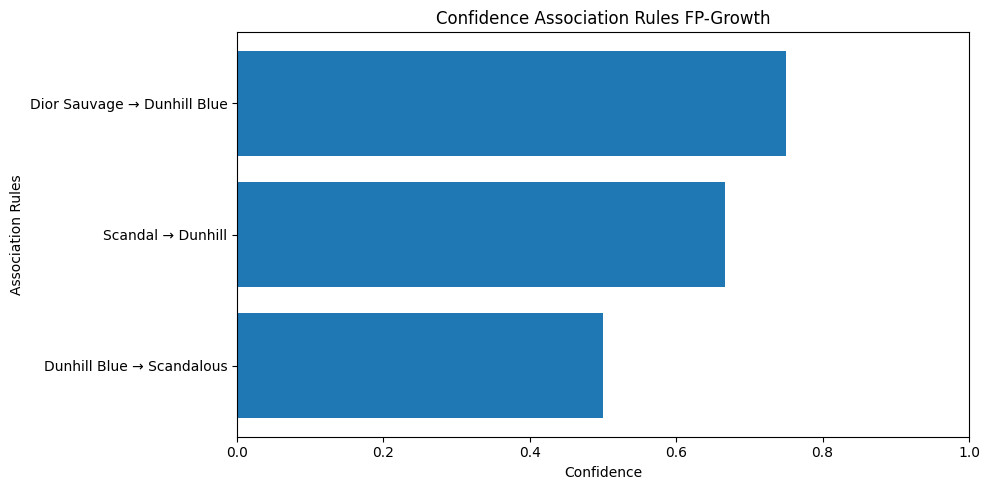

In [ ]:
import matplotlib.pyplot as plt

# Membuat label aturan asosiasi
rules['aturan'] = rules.apply(
    lambda row: f"{list(row['antecedents'])[0]} → "
                f"{list(row['consequents'])[0]}",
    axis=1
)

# Visualisasi confidence setiap aturan
plt.figure(figsize=(10, 5))

plt.barh(rules['aturan'], rules['confidence'])

plt.xlabel('Confidence')
plt.ylabel('Association Rules')
plt.title('Confidence Association Rules FP-Growth')
plt.xlim(0, 1)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### K-Means